In [2]:
%load_ext autoreload
%autoreload 2

from funkcje.funkcje import *
from funkcje.wskazniki_kredytowe import oblicz_wskazniki
from funkcje.do_pipeline import *

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [6]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score,average_precision_score, roc_auc_score, brier_score_loss, log_loss, roc_curve
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from scipy.special import logit, expit
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
#from xgboost import XGBClassifier

In [7]:
#Dane
df = pd.read_csv("zbior_1.csv")
#usuwam wybrane zmienne kategoryczne na podstawie tego co w eksploracja_danych.ipynb
X=df.iloc[:, :-1].drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis","schemat_wsk_bilans"])
X=oblicz_wskazniki(X)
y=df.iloc[:, -1]

#Podzil na zbior treningowy (70%) i pozostale
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=2137,
    stratify=y
)

#Podzil na zbior walidacyjny (15%) i testowy (15%)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=2137,
    stratify=y_temp
)

KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}
TARGET_PD = 0.04 

In [8]:

regresja_logistyczna_pipeline = Pipeline([
    ("przygotowanie_cech", PrzygotowanieCech([])),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegressionUjemne(
        l1_ratio=1, solver="liblinear", C=100, random_state=2137, max_iter=1000
    )),
])

In [9]:
params={'classifier__C': np.float64(0.1),
  'przygotowanie_cech__liczba_kwantyli': np.int64(10),
  'przygotowanie_cech__prog_auc': np.float64(0.55),
  'przygotowanie_cech__prog_korelacji': np.float64(0.7),
  'przygotowanie_cech__prog_monotonicznosci': np.float64(0.1),
  'przygotowanie_cech__prog_nan': np.float64(0.35),
  'przygotowanie_cech__prog_zer': np.float64(0.3),
  'przygotowanie_cech__tylko_wskazniki': np.False_}
regresja_logistyczna = clone(regresja_logistyczna_pipeline)
regresja_logistyczna.set_params(**params)
regresja_logistyczna.fit(X_train, y_train)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


,steps,"[('przygotowanie_cech', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,kolumny_do_pominiecia,[]
,prog_korelacji,np.float64(0.7)
,prog_auc,np.float64(0.55)
,tylko_wskazniki,np.False_
,prog_nan,np.float64(0.35)
,prog_zer,np.float64(0.3)
,prog_monotonicznosci,np.float64(0.1)


In [10]:
betas = regresja_logistyczna.named_steps["classifier"].coef_[0]
#liczb niezerowych bet
np.sum(betas != 0)

np.int64(28)

In [11]:
P = {"logit": {s: regresja_logistyczna.predict_proba(X)[:, 1] for s, X in [("train", X_train), ("valid", X_valid), ("test", X_test)]}}
print(f"AUC na zbiorze walidacyjnym: {roc_auc_score(y_valid, P['logit']['valid'])}")
print(f"AUC na zbiorze testowym: {roc_auc_score(y_test, P['logit']['test'])}")

AUC na zbiorze walidacyjnym: 0.8144512195121951
AUC na zbiorze testowym: 0.7654875538087218


In [ ]:
# Ocena na zbiorze walidacyjnym

wyniki_val, y_pred_proba_val, fpr, tpr, precision, recall = (
    ocena_modelu(
        regresja_logistyczna,
        X_valid,
        y_valid,
        nazwa="Regresja logistyczna"
    )
)

print(wyniki_val)

                      Metryka  Regresja logistyczna
0                     ROC AUC              0.814451
1  PR AUC (Average Precision)              0.349009
2                          KS              0.486585
3                    Log-loss              0.245598
4                 Brier score              0.069768


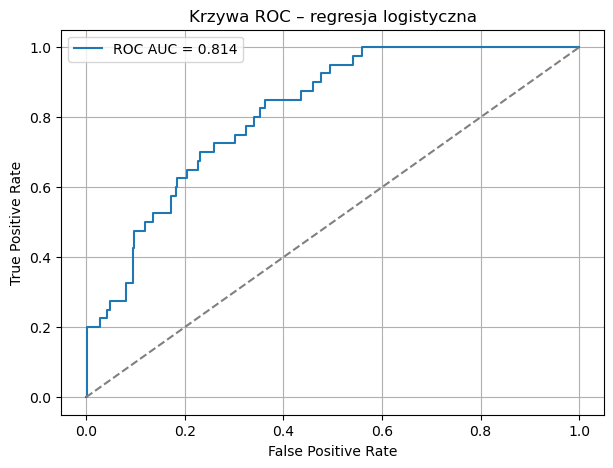

In [ ]:
# Wykres ROC

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {wyniki_val.iloc[0, 1]:.3f}"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Krzywa ROC – regresja logistyczna")
plt.legend()
plt.grid()
plt.show()

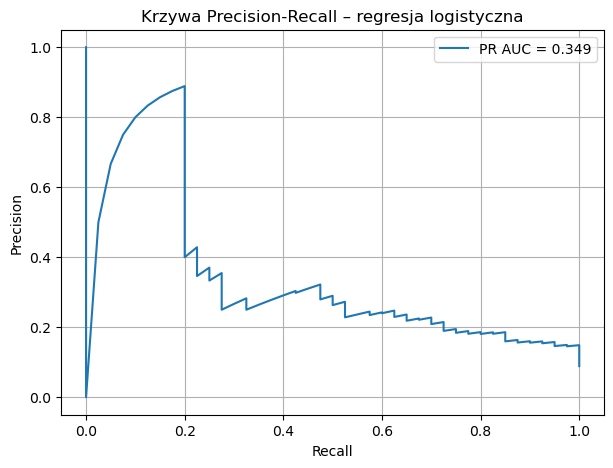

In [ ]:
# Wykres Precision-Recall

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"PR AUC = {wyniki_val.iloc[1, 1]:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Krzywa Precision-Recall – regresja logistyczna")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# współczynniki do poprawki !!!!!!!!!!

classifier = regresja_logistyczna.named_steps["classifier"]

features = regresja_logistyczna.named_steps[
    "przygotowanie_cech"
].get_feature_names_out()

coefs = pd.DataFrame({
    "feature": features,
    "coefficient": classifier.coef_[0]
})

coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs["abs_coefficient"] = coefs["coefficient"].abs()

coefs = coefs.sort_values(
    "abs_coefficient",
    ascending=False
)

display(coefs)

AttributeError: 'PrzygotowanieCech' object has no attribute 'get_feature_names_out'

In [ ]:
# wazność cech w modelu regresji logistycznej
# permutation importance

from sklearn.inspection import permutation_importance

result = permutation_importance(
    regresja_logistyczna,
    X_valid,
    y_valid,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42
)

importance = pd.DataFrame({
    "feature": X_valid.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

display(importance)

,feature,importance
212,wsk_zadluzenia,0.044957
6,Aktywa,0.040616
3,wsk_index_skr_zaw,0.034256
218,wsk_fin_majatku_kapitalem,0.017183
4,wsk_index_nowe,0.016274
...,...,...
110,wsk_marza_ebitda_2,-0.001360
131,wsk_zysk_operacyjny_zob_1,-0.001500
43,Zobowiazania_krotkoterminowe,-0.001616
166,wsk_ebitda_zobowiazan_3,-0.002055


Ponieważ używacie własnego preprocessingu, sprawdźcie, czy liczba i nazwy cech po transformacji odpowiadają oryginalnym kolumnom. Jeżeli PrzygotowanieCech usuwa lub przekształca zmienne, permutation importance liczone na wejściowych kolumnach będzie mierzyć ważność całych oryginalnych cech.

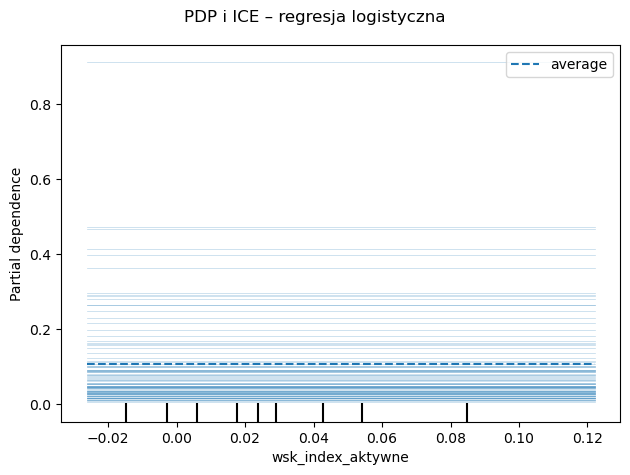

In [ ]:
# Krzywe PDP/ICE dla wsk_index_aktywne

from sklearn.inspection import PartialDependenceDisplay

features = ["wsk_index_aktywne"]

PartialDependenceDisplay.from_estimator(
    regresja_logistyczna,
    X_valid,
    features=features,
    kind="both",
    response_method="predict_proba",
    target=1,
    subsample=100,
    random_state=42
)

plt.suptitle("PDP i ICE – regresja logistyczna")
plt.tight_layout()
plt.show()

Pamiętajcie, że wykresy przedstawiają wpływ zmiennej na przewidywane PD, a nie na log-odds. Jeżeli preprocessing wykorzystuje WoE, interpretacja dotyczy wartości po transformacji.

PDP/ICE pokazują zależność predykcji od cech.

In [22]:
import pandas as pd
import numpy as np

# Wybrana obserwacja
i = 0

# Transformacja cech przez pipeline
prep = regresja_logistyczna.named_steps["przygotowanie_cech"]
imputer = regresja_logistyczna.named_steps["imputer"]
scaler = regresja_logistyczna.named_steps["scaler"]
classifier = regresja_logistyczna.named_steps["classifier"]

X_one = X_valid.iloc[[i]]

X_prep = prep.transform(X_one)
X_imputed = imputer.transform(X_prep)
X_scaled = scaler.transform(X_imputed)

# Współczynniki i wkłady
coefficients = classifier.coef_[0]
contributions = X_scaled[0] * coefficients

# Nazwy cech po preprocessingu
feature_names = classifier.feature_names_in_ if hasattr(
    classifier, "feature_names_in_"
) else [f"feature_{j}" for j in range(len(coefficients))]

# Tabela wkładów
contributions_df = pd.DataFrame({
    "feature": feature_names,
    "value": X_scaled[0],
    "coefficient": coefficients,
    "contribution": contributions
})

contributions_df["abs_contribution"] = (
    contributions_df["contribution"].abs()
)

contributions_df = contributions_df.sort_values(
    "abs_contribution",
    ascending=False
)

display(contributions_df)

,feature,value,coefficient,contribution,abs_contribution
38,feature_38,9.448545,-0.221807,-2.095755,2.095755
18,feature_18,-1.201526,-0.376286,0.452117,0.452117
5,feature_5,1.919251,-0.106617,-0.204625,0.204625
0,feature_0,-0.551762,-0.346999,0.191461,0.191461
8,feature_8,2.322768,-0.076271,-0.177160,0.177160
35,feature_35,0.366783,-0.421845,-0.154726,0.154726
26,feature_26,-0.385415,-0.296811,0.114395,0.114395
23,feature_23,-0.714184,-0.152931,0.109221,0.109221
41,feature_41,5.160579,-0.020170,-0.104088,0.104088
37,feature_37,0.644660,-0.098020,-0.063190,0.063190


Uwaga: jeśli PrzygotowanieCech zwraca macierz bez nazw kolumn, trzeba pobrać nazwy bezpośrednio z jego implementacji. Powyższy fragment zakłada też, że można uzyskać nazwy cech po imputacji i skalowaniu.

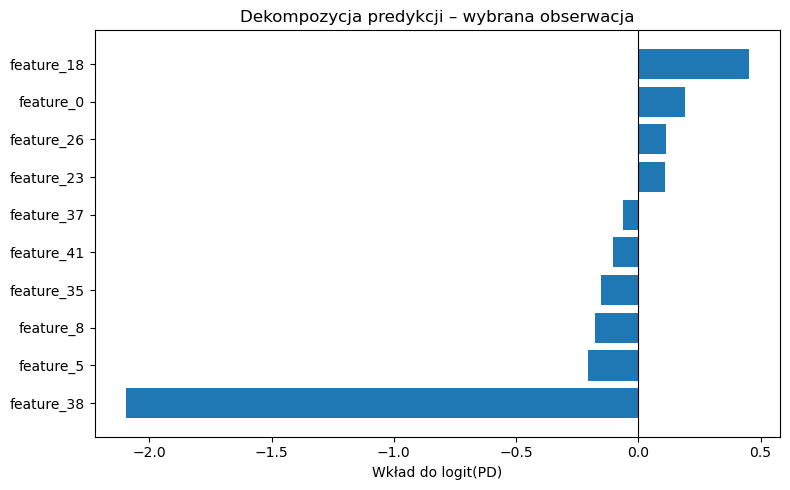

In [23]:
# Wykres wkładów cech

import matplotlib.pyplot as plt

plot_data = contributions_df.head(10).sort_values(
    "contribution"
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_data["feature"],
    plot_data["contribution"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Wkład do logit(PD)")
plt.title("Dekompozycja predykcji – wybrana obserwacja")
plt.tight_layout()
plt.show()

In [24]:
# Przejście od logitu do PD

logit = classifier.intercept_[0] + contributions.sum()

pd_pred = 1 / (1 + np.exp(-logit))

print("Logit:", logit)
print("Predicted PD:", pd_pred)

Logit: -4.448432171220623
Predicted PD: 0.011561655892258932


W ten sposób możecie wyjaśnić np.:
- dlaczego klient otrzymał PD = 12%;
- które zmienne najbardziej zwiększyły ryzyko;
- które zmienne obniżyły ryzyko;
- jaka była końcowa wartość logitu.

### Case studies – jakie obserwacje wybrać?

Proponuję wybrać 3–5 przypadków:

Przypadek	Cel analizy

Niskie PD

	Co sprawia, że model ocenia klienta jako niskiego ryzyka?

Wysokie PD

	Które cechy odpowiadają za wysokie ryzyko?

Przypadek graniczny

	Co decyduje o przypisaniu do jednej lub drugiej klasy ratingowej?

Nietypowy przypadek	

Czy model reaguje zgodnie z intuicją biznesową?